MNIST Image Classification Assignment
=====================================
Classical ML pipeline for handwritten digit recognition:
data loading -> preprocessing -> SGD baseline -> KNN + hyperparameter tuning
-> prediction visualization -> error analysis -> final comparison.

Attribution: the setup block, save_fig() and plot_digits() helpers are adapted
from Aurelien Geron, "Hands-On Machine Learning with Scikit-Learn, Keras, and
TensorFlow" (Chapter 3 notebook).



# **1. Setup**

In [ ]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# Fixed seed so results are reproducible across runs
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot styling
mpl.rc("axes", labelsize=14)
mpl.rc("xtick", labelsize=12)
mpl.rc("ytick", labelsize=12)

# Folder where figures are saved
IMAGES_PATH = os.path.join(".", "images", "classification_assignment")
os.makedirs(IMAGES_PATH, exist_ok=True)


#Save the current matplotlib figure into IMAGES_PATH
def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)


#Plot a single flattened 784-pixel digit as a 28x28 image
def plot_digit(data):
    plt.imshow(data.reshape(28, 28), cmap=mpl.cm.binary, interpolation="nearest")
    plt.axis("off")


#Plot many digits as one big grid image
def plot_digits(instances, images_per_row=10, **options):
    size = 28
    images_per_row = min(len(instances), images_per_row)
    n_rows = (len(instances) - 1) // images_per_row + 1

    # Pad with blank images so the grid is rectangular
    n_empty = n_rows * images_per_row - len(instances)
    padded = np.concatenate([instances, np.zeros((n_empty, size * size))], axis=0)

    # Rearrange into one large image
    grid = padded.reshape((n_rows, images_per_row, size, size))
    big_image = grid.transpose(0, 2, 1, 3).reshape(n_rows * size, images_per_row * size)

    plt.imshow(big_image, cmap=mpl.cm.binary, **options)
    plt.axis("off")

# 2. DATA PREPARATION

## Load, explore and split MNIST

Data shape: (70000, 784) | Labels shape: (70000,)
Saving figure some_digit_plot


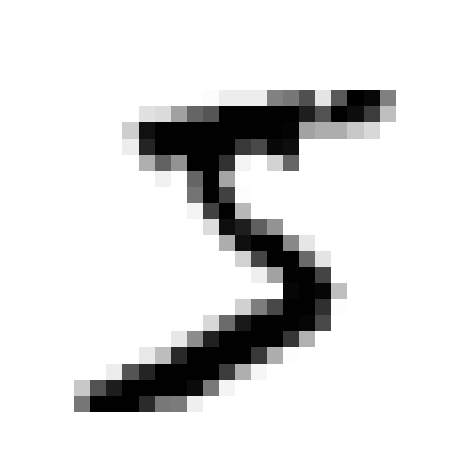

Label of the first image: 5
Saving figure more_digits_plot


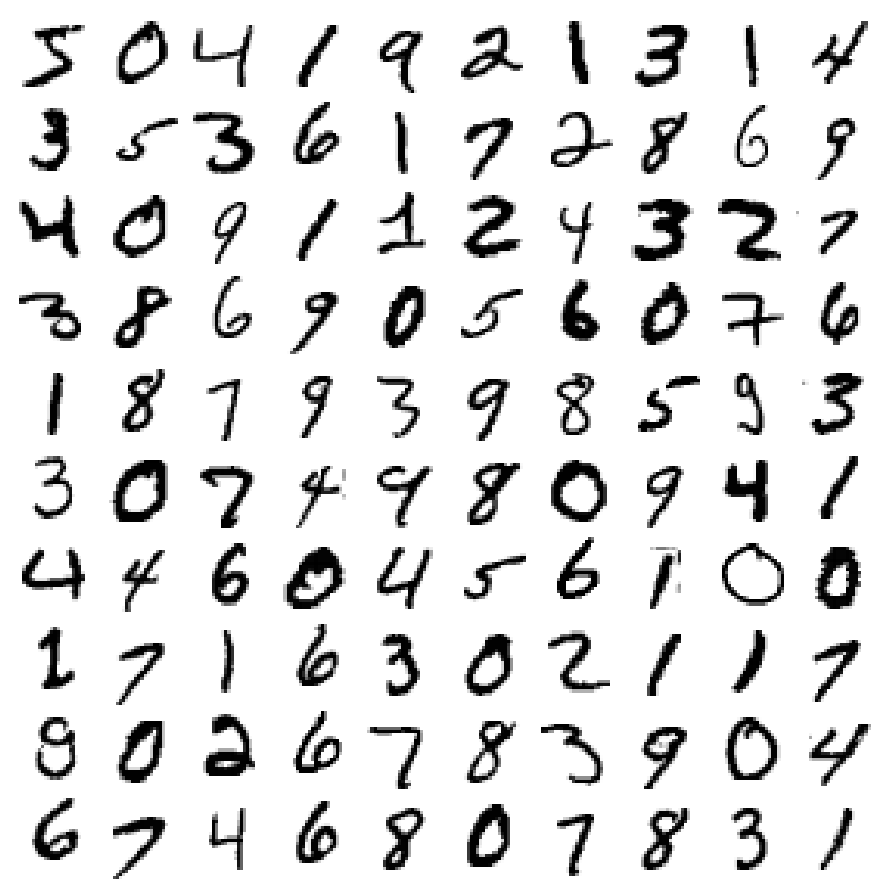

Train/test shapes: (60000, 784) (10000, 784)


In [ ]:
from sklearn.datasets import fetch_openml

# --- 2.1 Load MNIST (70,000 images, 784 pixel features each) ---
mnist = fetch_openml("mnist_784", version=1, as_frame=False)
X, y = mnist["data"], mnist["target"]
print("Data shape:", X.shape, "| Labels shape:", y.shape)

# Labels come as strings -> convert to integers
y = y.astype(np.uint8)

# --- 2.2 Visualize one sample digit ---
some_digit = X[0]
plt.figure()
plot_digit(some_digit)
save_fig("some_digit_plot")
plt.show()
print("Label of the first image:", y[0])

# --- 2.3 Visualize a grid of 100 sample digits ---
plt.figure(figsize=(9, 9))
plot_digits(X[:100], images_per_row=10)
save_fig("more_digits_plot")
plt.show()

# --- 2.4 Train / test split (standard MNIST split: 60k train, 10k test) ---
X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]
print("Train/test shapes:", X_train.shape, X_test.shape)

## Check data distribution

Saving figure class_distribution


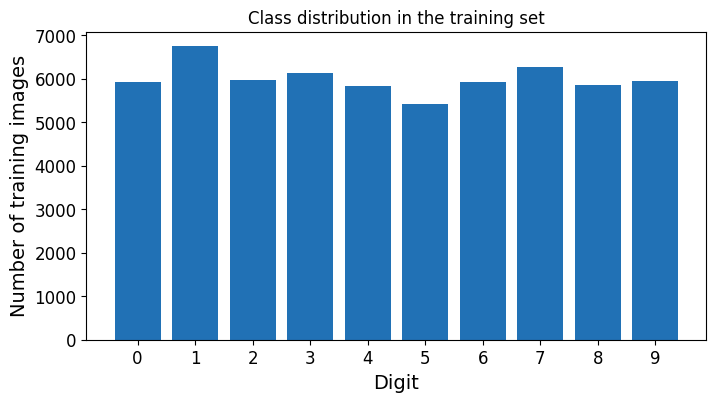

In [ ]:
# Count how many training images each digit has
plt.figure(figsize=(8, 4))
plt.hist(y_train.astype(int), bins=np.arange(11) - 0.5, rwidth=0.8, color="#2171b5")

# Label the axes and show one tick per digit
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Number of training images")
plt.title("Class distribution in the training set")
save_fig("class_distribution", tight_layout=False)
plt.show()

## Check for data type and missing data and fix the issues


In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# --- Shapes and types ---
print("X_train:", X_train.shape, X_train.dtype, "| X_test:", X_test.shape, X_test.dtype)
print("y_train:", y_train.shape, y_train.dtype, "| y_test:", y_test.shape, y_test.dtype)
print(f"Memory: X_train = {X_train.nbytes / 1e6:.1f} MB")

# --- Features: fix the type, then report quality ---
if X_train.dtype == object:
    print("FEEDBACK: features are text -> one-hot encoding")
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_train)
    X_train, X_test = enc.transform(X_train), enc.transform(X_test)
elif not np.issubdtype(X_train.dtype, np.number):
    print("FEEDBACK: unexpected feature type -> converting to float")
    X_train, X_test = X_train.astype(float), X_test.astype(float)
else:
    print("OK: features are numeric")

# Check missing / infinite values and the pixel value range
print("Missing values (train/test):", np.isnan(X_train).sum(), "/", np.isnan(X_test).sum())
print("Infinite values (train):", np.isinf(X_train).sum())
print(f"Pixel range: min = {X_train.min():.0f}, max = {X_train.max():.0f} (expected 0 to 255)")
print("Whole-number pixels:", bool(np.all(X_train == X_train.astype(int))))

# --- Labels: fix the type, then report classes ---
if y_train.dtype == object:
    print("FEEDBACK: labels are text -> converting to integers (0-9)")
    y_train, y_test = y_train.astype(np.uint8), y_test.astype(np.uint8)
elif np.issubdtype(y_train.dtype, np.integer):
    print("OK: labels are integers")
else:
    print("FEEDBACK: unexpected label type -> converting to integers")
    y_train, y_test = y_train.astype(np.uint8), y_test.astype(np.uint8)

# List the classes and how many images each has in train and test
print("Classes:", np.unique(y_train))
print(pd.DataFrame({"train": pd.Series(y_train).value_counts().sort_index(),
                    "test": pd.Series(y_test).value_counts().sort_index()}))

# --- Final check: samples line up and types are correct ---
assert len(X_train) == len(y_train) and len(X_test) == len(y_test), "X and y sizes differ"
print("After: X", X_train.dtype, "| y", y_train.dtype)

X_train: (60000, 784) int64 | X_test: (10000, 784) int64
y_train: (60000,) uint8 | y_test: (10000,) uint8
Memory: X_train = 376.3 MB
OK: features are numeric
Missing values (train/test): 0 / 0
Infinite values (train): 0
Pixel range: min = 0, max = 255 (expected 0 to 255)
Whole-number pixels: True
OK: labels are integers
Classes: [0 1 2 3 4 5 6 7 8 9]
   train  test
0   5923   980
1   6742  1135
2   5958  1032
3   6131  1010
4   5842   982
5   5421   892
6   5918   958
7   6265  1028
8   5851   974
9   5949  1009
After: X int64 | y uint8


# 3. DATA PREPROCESSING

In [ ]:
from sklearn.preprocessing import StandardScaler

# Scale features to zero mean / unit variance (used for the SGD classifier).
# The scaler is fit on training data only, then applied to the test data,
# to avoid leaking test information.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype(np.float64))
X_test_scaled = scaler.transform(X_test.astype(np.float64))
print("Scaled shapes:", X_train_scaled.shape, X_test_scaled.shape)

# Note: KNN below is trained on the raw pixels. All pixels already share the
# same 0-255 range, so distance-based KNN does not need standardization.

Scaled shapes: (60000, 784) (10000, 784)


# 4. BASELINE MODEL: SGD CLASSIFIER

In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create the baseline SGD classifier (fixed seed for reproducible results)
sgd_clf = SGDClassifier(max_iter=1000, tol=1e-3, random_state=RANDOM_STATE)

### 4.1 Cross-validation accuracy: unscaled vs scaled data

In [ ]:
# 3-fold cross-validation accuracy on unscaled vs scaled training data
sgd_cv_unscaled = cross_val_score(sgd_clf, X_train, y_train, cv=3, scoring="accuracy")
sgd_cv_scaled = cross_val_score(sgd_clf, X_train_scaled, y_train, cv=3, scoring="accuracy")
print("SGD CV accuracy (unscaled):", sgd_cv_unscaled, "| mean:", sgd_cv_unscaled.mean())
print("SGD CV accuracy (scaled):  ", sgd_cv_scaled, "| mean:", sgd_cv_scaled.mean())

SGD CV accuracy (unscaled): [0.87365 0.85835 0.8689 ] | mean: 0.8669666666666668
SGD CV accuracy (scaled):   [0.8983 0.891  0.9018] | mean: 0.8970333333333333


### 4.2 Final evaluation on the test set (scaled data)

In [ ]:
# Train the SGD classifier on the full scaled training set
sgd_clf.fit(X_train_scaled, y_train)

# Predict digit labels for the scaled test images
y_test_pred_sgd = sgd_clf.predict(X_test_scaled)

# Compute the fraction of test images classified correctly
sgd_test_accuracy = accuracy_score(y_test, y_test_pred_sgd)
print("SGD test accuracy (scaled):", sgd_test_accuracy)

SGD test accuracy (scaled): 0.8933


### 4.3 Confusion matrix (from cross-validated predictions on training data)

In [ ]:
# Get out-of-fold predictions for every training image (3-fold CV), so no image is predicted by a model that saw it
y_train_pred_sgd = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv=3)

# Build the confusion matrix: rows = true digits, columns = predicted digits
conf_mx_sgd = confusion_matrix(y_train, y_train_pred_sgd)
print(conf_mx_sgd)

[[5577    0   22    5    8   43   36    6  225    1]
 [   0 6400   37   24    4   44    4    7  212   10]
 [  27   27 5220   92   73   27   67   36  378   11]
 [  22   17  117 5227    2  203   27   40  403   73]
 [  12   14   41    9 5182   12   34   27  347  164]
 [  27   15   30  168   53 4444   75   14  535   60]
 [  30   15   42    3   44   97 5552    3  131    1]
 [  21   10   51   30   49   12    3 5684  195  210]
 [  17   63   48   86    3  126   25   10 5429   44]
 [  25   18   30   64  118   36    1  179  371 5107]]


Saving figure sgd_confusion_matrix_plot


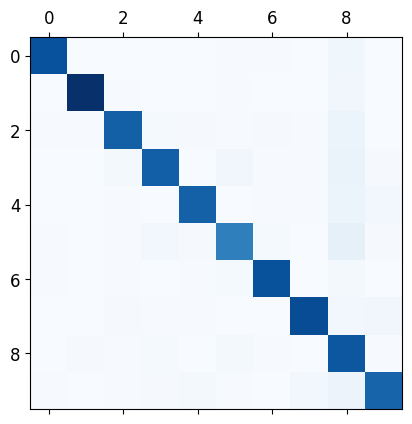

In [ ]:
# Show the matrix as a grayscale image (brighter cell = more samples) and save it
plt.matshow(conf_mx_sgd, cmap=plt.cm.Blues)
save_fig("sgd_confusion_matrix_plot", tight_layout=False)
plt.show()

### 4.4 Normalized confusion matrix showing only the errors

Saving figure sgd_confusion_matrix_errors_plot


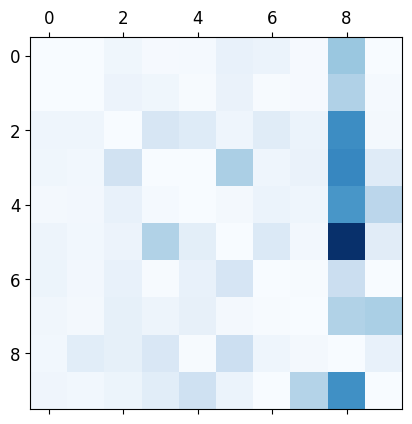

In [ ]:
# Total number of images per true digit (sum of each row)
row_sums = conf_mx_sgd.sum(axis=1, keepdims=True)

# Normalize: convert counts to error rates relative to each class size
norm_conf_mx_sgd = conf_mx_sgd / row_sums

# Zero the diagonal (correct predictions) so only errors remain
np.fill_diagonal(norm_conf_mx_sgd, 0)

# Plot the error matrix: brighter cell = more frequent confusion; then save it
plt.matshow(norm_conf_mx_sgd, cmap=plt.cm.Blues)
save_fig("sgd_confusion_matrix_errors_plot", tight_layout=False)
plt.show()


# 5. HYPERPARAMETER TUNING: KNN + GRIDSEARCHCV

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

### 5.1 Default KNN (before tuning)

In [ ]:
knn_default = KNeighborsClassifier()
knn_default.fit(X_train, y_train)
knn_default_accuracy = accuracy_score(y_test, knn_default.predict(X_test))
print("Default KNN test accuracy:", knn_default_accuracy)

Default KNN test accuracy: 0.9688


### 5.2 Grid search over n_neighbors and weights (5-fold CV)

In [ ]:
# NOTE: slow (~40s per fit x 30 fits). Widen the grid only if you have time.
param_grid = [{"weights": ["uniform", "distance"], "n_neighbors": [3, 4, 5]}]
grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, verbose=3)
grid_search.fit(X_train, y_train)

print("Best hyperparameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV 1/5] END ....n_neighbors=3, weights=uniform;, score=0.972 total time=  40.5s
[CV 2/5] END ....n_neighbors=3, weights=uniform;, score=0.971 total time=  40.9s
[CV 3/5] END ....n_neighbors=3, weights=uniform;, score=0.969 total time=  42.1s
[CV 4/5] END ....n_neighbors=3, weights=uniform;, score=0.969 total time=  41.9s
[CV 5/5] END ....n_neighbors=3, weights=uniform;, score=0.970 total time=  42.0s
[CV 1/5] END ...n_neighbors=3, weights=distance;, score=0.972 total time=  42.0s
[CV 2/5] END ...n_neighbors=3, weights=distance;, score=0.972 total time=  41.3s
[CV 3/5] END ...n_neighbors=3, weights=distance;, score=0.970 total time=  42.0s
[CV 4/5] END ...n_neighbors=3, weights=distance;, score=0.970 total time=  41.9s
[CV 5/5] END ...n_neighbors=3, weights=distance;, score=0.971 total time=  42.2s
[CV 1/5] END ....n_neighbors=4, weights=uniform;, score=0.969 total time=  42.2s
[CV 2/5] END ....n_neighbors=4, weights=uniform;,

### 5.3 Impact of every hyperparameter combination

In [ ]:
print("\nAll parameter combinations (mean CV accuracy):")
results = grid_search.cv_results_
for params, mean, std in zip(results["params"], results["mean_test_score"],
                             results["std_test_score"]):
    print(f"  {params}  ->  {mean:.4f} (+/- {std:.4f})")


All parameter combinations (mean CV accuracy):
  {'n_neighbors': 3, 'weights': 'uniform'}  ->  0.9701 (+/- 0.0012)
  {'n_neighbors': 3, 'weights': 'distance'}  ->  0.9711 (+/- 0.0009)
  {'n_neighbors': 4, 'weights': 'uniform'}  ->  0.9685 (+/- 0.0011)
  {'n_neighbors': 4, 'weights': 'distance'}  ->  0.9716 (+/- 0.0011)
  {'n_neighbors': 5, 'weights': 'uniform'}  ->  0.9693 (+/- 0.0007)
  {'n_neighbors': 5, 'weights': 'distance'}  ->  0.9704 (+/- 0.0006)


### 5.4 Evaluate the tuned KNN on the test set

In [ ]:
best_knn = grid_search.best_estimator_
y_test_pred_knn = best_knn.predict(X_test)
knn_test_accuracy = accuracy_score(y_test, y_test_pred_knn)
print("Tuned KNN test accuracy:", knn_test_accuracy)
print("Gain over default KNN:", knn_test_accuracy - knn_default_accuracy)

Tuned KNN test accuracy: 0.9714
Gain over default KNN: 0.0026000000000000467


### 5.5 Confusion matrix and per-class metrics for the tuned KNN

[[ 973    1    1    0    0    1    3    1    0    0]
 [   0 1132    2    0    0    0    1    0    0    0]
 [  10    5  995    2    1    0    0   16    3    0]
 [   0    1    3  974    1   14    1    7    4    5]
 [   1    5    0    0  950    0    4    3    0   19]
 [   4    0    0    9    2  862    7    1    3    4]
 [   4    2    0    0    3    3  946    0    0    0]
 [   0   17    4    0    3    0    0  994    0   10]
 [   5    2    4   14    5   11    4    4  920    5]
 [   3    4    2    7    9    4    1   10    1  968]]
Saving figure knn_confusion_matrix_plot


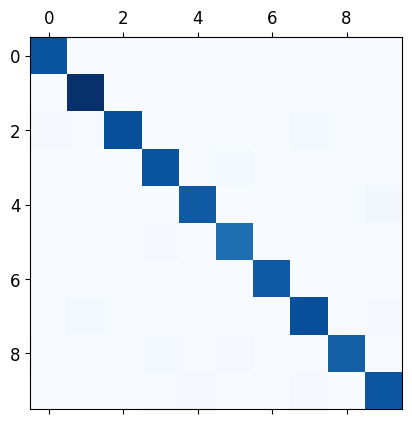

              precision    recall  f1-score   support

           0     0.9730    0.9929    0.9828       980
           1     0.9683    0.9974    0.9826      1135
           2     0.9842    0.9641    0.9741      1032
           3     0.9682    0.9644    0.9663      1010
           4     0.9754    0.9674    0.9714       982
           5     0.9631    0.9664    0.9647       892
           6     0.9783    0.9875    0.9829       958
           7     0.9595    0.9669    0.9632      1028
           8     0.9882    0.9446    0.9659       974
           9     0.9575    0.9594    0.9584      1009

    accuracy                         0.9714     10000
   macro avg     0.9716    0.9711    0.9712     10000
weighted avg     0.9715    0.9714    0.9714     10000



In [ ]:
conf_mx_knn = confusion_matrix(y_test, y_test_pred_knn)
print(conf_mx_knn)

plt.matshow(conf_mx_knn, cmap=plt.cm.Blues)
save_fig("knn_confusion_matrix_plot", tight_layout=False)
plt.show()

print(classification_report(y_test, y_test_pred_knn, digits=4))

# 6. VISUALIZATION OF PREDICTIONS

Saving figure random_test_predictions


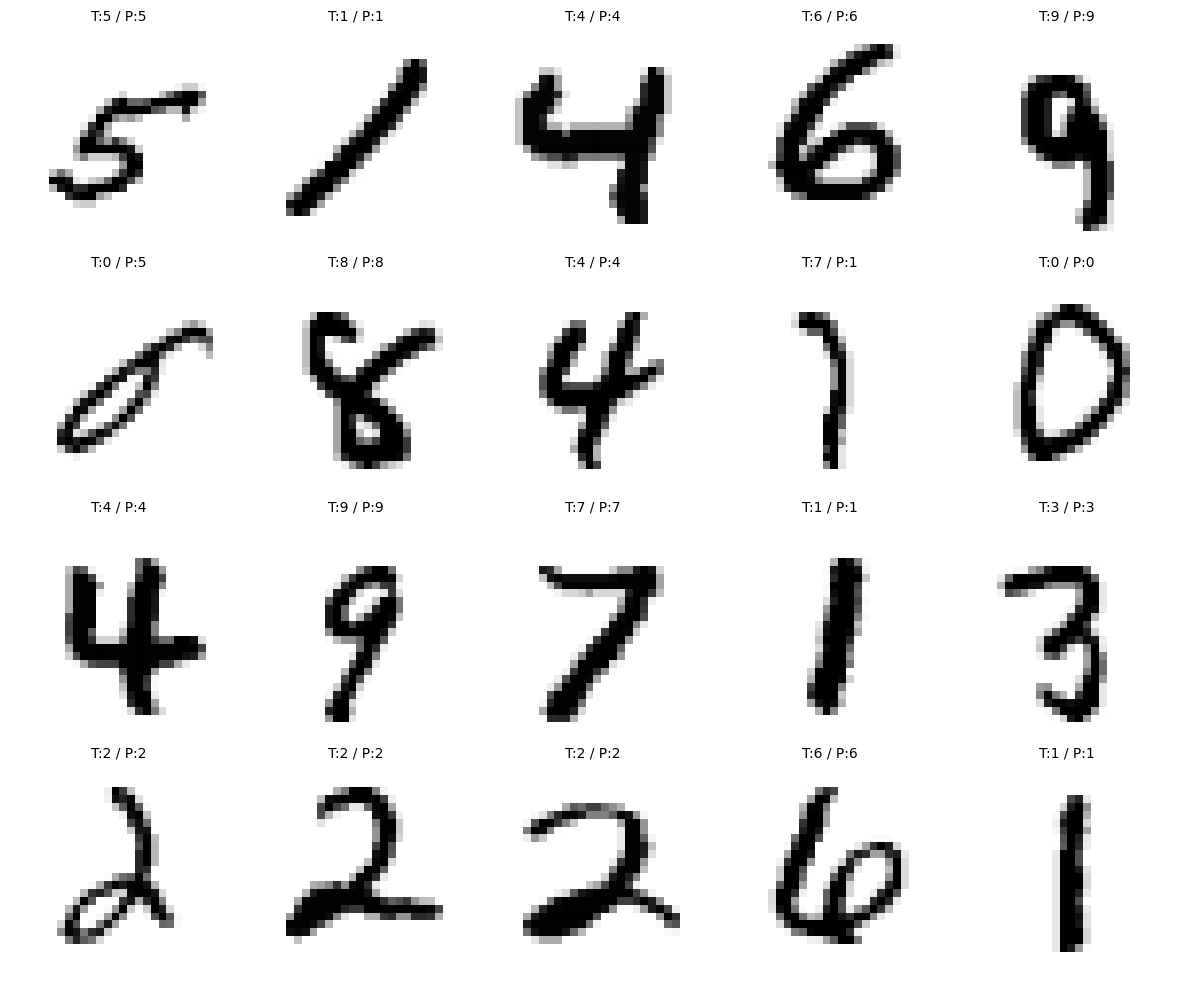

Total misclassified test images: 286
Saving figure misclassified_test_predictions


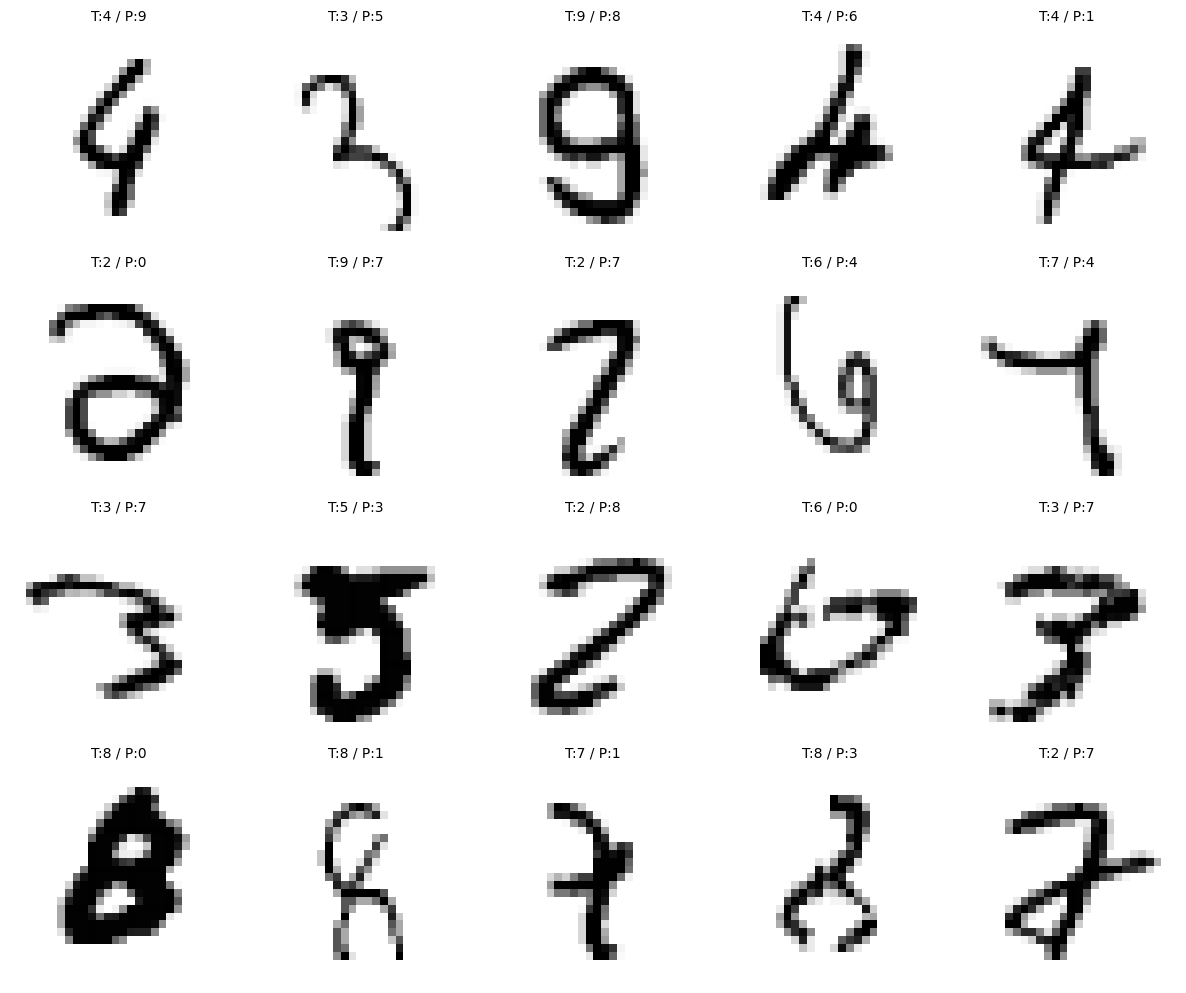

In [ ]:
# Seeded RNG so the same 20 test images are shown every run
rng = np.random.default_rng(RANDOM_STATE)
random_test_idx = rng.permutation(len(X_test))[:20]

plt.figure(figsize=(12, 10))
for plot_index, image_index in enumerate(random_test_idx):
    plt.subplot(4, 5, plot_index + 1)
    plt.imshow(X_test[image_index].reshape(28, 28), cmap=mpl.cm.binary)
    plt.title(f"T:{y_test[image_index]} / P:{y_test_pred_knn[image_index]}", fontsize=10)
    plt.axis("off")
save_fig("random_test_predictions")
plt.show()

# Misclassified test images only (the "challenging cases")
wrong_idx = np.where(y_test != y_test_pred_knn)[0]
print(f"Total misclassified test images: {len(wrong_idx)}")

plt.figure(figsize=(12, 10))
for plot_index, image_index in enumerate(wrong_idx[:20]):
    plt.subplot(4, 5, plot_index + 1)
    plt.imshow(X_test[image_index].reshape(28, 28), cmap=mpl.cm.binary)
    plt.title(f"T:{y_test[image_index]} / P:{y_test_pred_knn[image_index]}", fontsize=10)
    plt.axis("off")
save_fig("misclassified_test_predictions")
plt.show()

# 7. ERROR ANALYSIS: MOST CONFUSED DIGIT PAIR

Most confused true/predicted pair:
True digit: 4 | Predicted as: 9
Number of such errors: 19
Saving figure knn_error_analysis_digits_plot


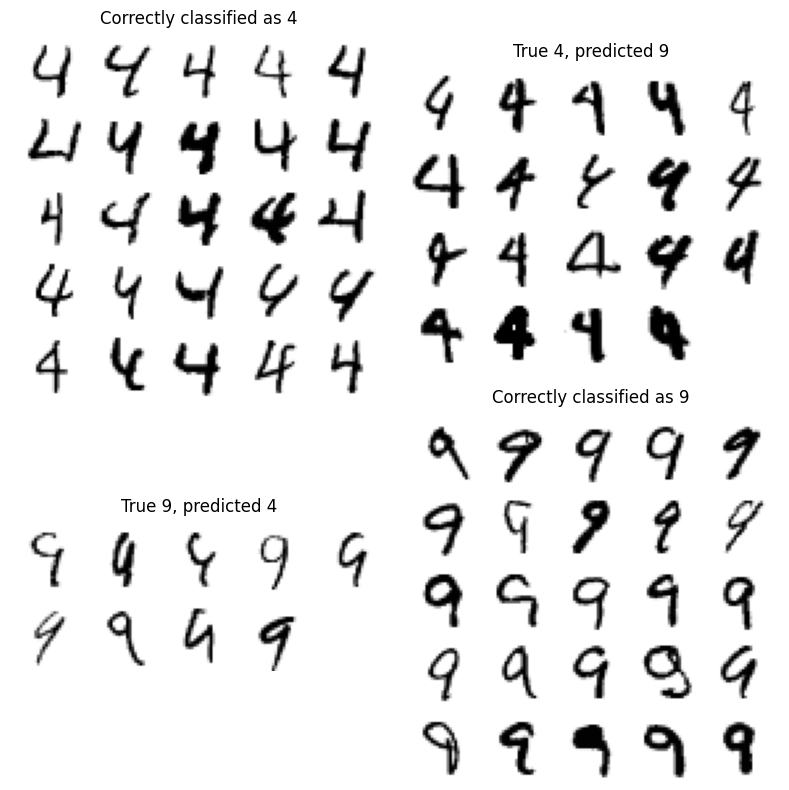

In [ ]:
# Find the largest off-diagonal entry of the KNN confusion matrix
conf_pair_matrix = conf_mx_knn.copy()
np.fill_diagonal(conf_pair_matrix, 0)
cl_a, cl_b = np.unravel_index(np.argmax(conf_pair_matrix), conf_pair_matrix.shape)

print("Most confused true/predicted pair:")
print("True digit:", cl_a, "| Predicted as:", cl_b)
print("Number of such errors:", conf_pair_matrix[cl_a, cl_b])

# Split test images into the four (true, predicted) groups
X_aa = X_test[(y_test == cl_a) & (y_test_pred_knn == cl_a)]
X_ab = X_test[(y_test == cl_a) & (y_test_pred_knn == cl_b)]
X_ba = X_test[(y_test == cl_b) & (y_test_pred_knn == cl_a)]
X_bb = X_test[(y_test == cl_b) & (y_test_pred_knn == cl_b)]

plt.figure(figsize=(8, 8))
plt.subplot(221); plot_digits(X_aa[:25], images_per_row=5)
plt.title(f"Correctly classified as {cl_a}")
plt.subplot(222); plot_digits(X_ab[:25], images_per_row=5)
plt.title(f"True {cl_a}, predicted {cl_b}")
plt.subplot(223); plot_digits(X_ba[:25], images_per_row=5)
plt.title(f"True {cl_b}, predicted {cl_a}")
plt.subplot(224); plot_digits(X_bb[:25], images_per_row=5)
plt.title(f"Correctly classified as {cl_b}")
save_fig("knn_error_analysis_digits_plot")
plt.show()

# 8. FINAL COMPARISON

In [ ]:
print("=" * 70)
print("FINAL RESULTS SUMMARY")
print("=" * 70)
print(f"SGD mean CV accuracy (unscaled): {sgd_cv_unscaled.mean():.4f}")
print(f"SGD mean CV accuracy (scaled):   {sgd_cv_scaled.mean():.4f}")
print(f"SGD test accuracy (scaled):      {sgd_test_accuracy:.4f}")
print("-" * 70)
print(f"Default KNN test accuracy:       {knn_default_accuracy:.4f}")
print(f"Best KNN hyperparameters:        {grid_search.best_params_}")
print(f"Best KNN CV score:               {grid_search.best_score_:.4f}")
print(f"Tuned KNN test accuracy:         {knn_test_accuracy:.4f}")
print(f"Improvement over default KNN:    {knn_test_accuracy - knn_default_accuracy:.4f}")
print("=" * 70)



FINAL RESULTS SUMMARY
SGD mean CV accuracy (unscaled): 0.8670
SGD mean CV accuracy (scaled):   0.8970
SGD test accuracy (scaled):      0.8933
----------------------------------------------------------------------
Default KNN test accuracy:       0.9688
Best KNN hyperparameters:        {'n_neighbors': 4, 'weights': 'distance'}
Best KNN CV score:               0.9716
Tuned KNN test accuracy:         0.9714
Improvement over default KNN:    0.0026


## Histogram for data

Saving figure accuracy_evolution


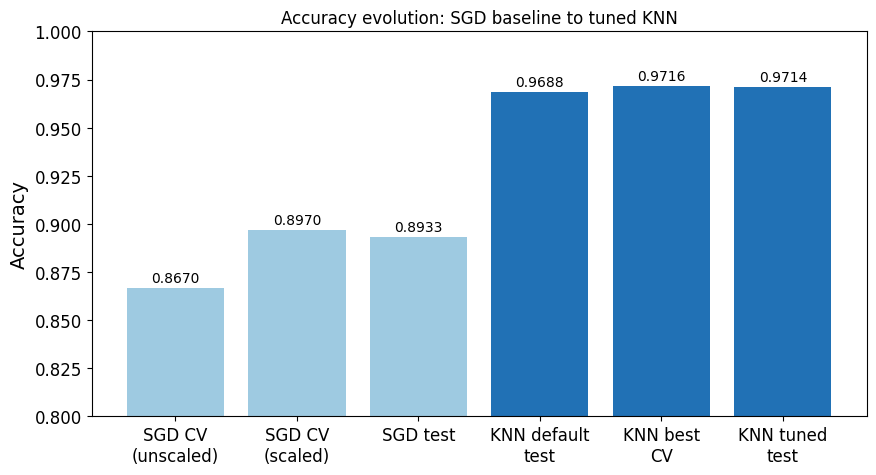

In [ ]:
# Collect each stage's accuracy in the order it was obtained
stages = ["SGD CV\n(unscaled)", "SGD CV\n(scaled)", "SGD test", "KNN default\ntest", "KNN best\nCV", "KNN tuned\ntest"]
scores = [sgd_cv_unscaled.mean(), sgd_cv_scaled.mean(), sgd_test_accuracy,
          knn_default_accuracy, grid_search.best_score_, knn_test_accuracy]

# Draw the bars (darker blue = KNN) and label each one with its value
colors = ["#9ecae1"] * 3 + ["#2171b5"] * 3
plt.figure(figsize=(10, 5))
bars = plt.bar(stages, scores, color=colors)
for bar, s in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width() / 2, s + 0.003, f"{s:.4f}", ha="center")

# Zoom the y-axis so the differences are visible, then add labels and save
plt.ylim(0.8, 1.0)
plt.ylabel("Accuracy")
plt.title("Accuracy evolution: SGD baseline to tuned KNN")
save_fig("accuracy_evolution", tight_layout=False)
plt.show()